# 05 Task 5: maximum flow
**Problem.** For each sector $V_s$ (task 3) take the sub-network of its open pipes, the source $s$ as origin and the farthest node $t_s$ (task 4) as destination. Each pipe has capacity $c(u,v)$ (the third edge attribute) and may carry water in either direction. Find a flow $f$ that maximises the amount leaving $s$, subject to $|f(u,v)|\le c(u,v)$ and conservation at every node other than $s$ and $t_s$; then find the pipes that limit it.

**Input:** sector sub-network, capacities, $s$, $t_s$. **Output:** maximum flow value, flow on each pipe, and a minimum cut (the bottleneck pipes).

**Technique: network flow.** An undirected pipe is modelled as two opposite arcs of capacity $c$ in a residual graph. Ford-Fulkerson augments along residual $s$-$t$ paths until none remains; by the max-flow min-cut theorem the final value equals the capacity of the cut separating the nodes still reachable from $s$. Two implementations are compared: **Edmonds-Karp** (BFS picks a shortest augmenting path, $O(VE^2)$) and **Dinic** (BFS builds a level graph, DFS pushes a blocking flow through it, $O(V^2E)$).

**Shortest path versus maximum flow.** Task 4 found one route minimising total *length*; capacities played no role. Maximum flow ignores length and asks how much water *all* routes together can carry, limited by *capacities*. A single route can carry at most its narrowest pipe; the maximum flow can be larger when parallel routes exist, and it is limited by the narrowest *cut*, not the narrowest pipe on one route.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import inspect
from collections import defaultdict
import matplotlib.pyplot as plt
import networkx as nx
import water
from water import flow, plot, tasks

plot.setup()
nets = water.load_all()
secs = {name: tasks.sectorize(net) for name, net in nets.items()}
fars = {name: tasks.farthest(net, secs[name]) for name, net in nets.items()}

In [2]:
print(inspect.getsource(flow.edmonds_karp))
print(inspect.getsource(flow.dinic))

def edmonds_karp(pipes, s, t):
    """ford-fulkerson with bfs augmenting paths: each augmentation uses a shortest
    path (in arcs) of the residual graph."""
    r = residual_graph(pipes)
    value, augmentations = 0.0, 0
    while True:
        parent = {s: None}
        queue = deque([s])
        while queue and t not in parent:
            u = queue.popleft()
            for v, cap in r[u].items():
                if cap > 1e-12 and v not in parent:
                    parent[v] = u
                    queue.append(v)
        if t not in parent:
            break
        path, v = [], t
        while parent[v] is not None:
            path.append((parent[v], v))
            v = parent[v]
        push = min(r[u][v] for u, v in path)
        for u, v in path:
            r[u][v] -= push
            r[v][u] += push
        value += push
        augmentations += 1
    return value, r, {'augmentations': augmentations}

def dinic(pipes, s, t):
    """bfs builds a level graph, dfs pushes 

## Correctness
For every sector: Edmonds-Karp and Dinic return the same value, equal to `networkx.maximum_flow_value`; the flow respects every capacity and is conserved at every intermediate node; and the minimum cut found from the final residual graph has capacity equal to the flow value (max-flow min-cut).

In [3]:
res = {}
for name, net in nets.items():
    ek = tasks.sector_flows(net, secs[name], fars[name], flow.edmonds_karp)
    dn = tasks.sector_flows(net, secs[name], fars[name], flow.dinic)
    for s in ek:
        a, b = ek[s], dn[s]
        H = nx.Graph(); H.add_edges_from((u, v, {'capacity': c}) for u, v, c in a['pipes'])
        assert abs(a['value'] - b['value']) < 1e-9 and abs(nx.maximum_flow_value(H, s, a['sink']) - a['value']) < 1e-9
        assert abs(sum(c for *_, c in b['cut']) - b['value']) < 1e-9
        for r in (a, b):
            net_out = defaultdict(float)
            for (u, v), f in r['flows'].items():
                c = next(c for x, y, c in r['pipes'] if (x, y) == (u, v))
                assert abs(f) <= c + 1e-9
                net_out[u] += f; net_out[v] -= f
            assert all(abs(x) < 1e-9 for u, x in net_out.items() if u not in (s, r['sink']))
            assert abs(net_out[s] - r['value']) < 1e-9
    res[name] = (ek, dn)
print('all checks passed')

all checks passed


## Results and bottlenecks
For each sector we report the maximum flow, the bottleneck pipes of the minimum cut, the capacity of the task 4 shortest route on its own (its narrowest pipe), and the operation counts of both algorithms. To see how capacities constrain the flow, the cut pipes are then made unlimited and the flow recomputed: the new value is set by the next bottleneck.

In [4]:
rows = []
for name, net in nets.items():
    ek, dn = res[name]
    for s, r in dn.items():
        cap = {frozenset((u, v)): c for u, v, c in r['pipes']}
        route = fars[name][s]['route']
        route_cap = min(cap[frozenset(e)] for e in zip(route, route[1:]))
        big = sum(cap.values())
        cut_keys = {frozenset(p[:2]) for p in r['cut']}
        relaxed = [(u, v, big if frozenset((u, v)) in cut_keys else c) for u, v, c in r['pipes']]
        nxt, rr, _ = flow.dinic(relaxed, s, r['sink'])
        _, nxt_cut = flow.min_cut(relaxed, rr, s)
        cut = ', '.join(f'{u}-{v} ({c:g})' for u, v, c in r['cut'])
        print(f'{name} {s} -> {r["sink"]}: max flow {r["value"]:g} | cut {cut} | shortest route alone {route_cap:g} | '
              f'EK {ek[s]["stats"]["augmentations"]} augmentations, Dinic {r["stats"]["phases"]} phases / '
              f'{r["stats"]["augmentations"]} augmentations | next bottleneck {nxt:g} at '
              f'{", ".join(f"{u}-{v}" for u, v, _ in nxt_cut)}')
        rows.append([name, f'{s} $\\to$ {r["sink"]}', r['value'], cut, route_cap,
                     ek[s]['stats']['augmentations'], f'{r["stats"]["phases"]} / {r["stats"]["augmentations"]}', nxt])

plot.table('flows', rows,
           ['Inst.', '$s\\to t_s$', 'Max flow', 'Min cut (capacity)', 'Route', 'EK aug.', 'Dinic ph./aug.', 'Next'],
           ['{}', '{}', '{:g}', '{}', '{:g}', '{}', '{}', '{:g}'])

NYT 17 -> 3: max flow 73 | cut 10-17 (73) | shortest route alone 73 | EK 1 augmentations, Dinic 1 phases / 1 augmentations | next bottleneck 133 at 8-9
NYT 19 -> 2: max flow 61 | cut 18-19 (61) | shortest route alone 61 | EK 1 augmentations, Dinic 1 phases / 1 augmentations | next bottleneck 75 at 12-18
HAN 13 -> 8: max flow 16 | cut 12-13 (16) | shortest route alone 16 | EK 1 augmentations, Dinic 1 phases / 1 augmentations | next bottleneck 16 at 11-12
HAN 1 -> 31: max flow 16 | cut 1-2 (16) | shortest route alone 16 | EK 1 augmentations, Dinic 1 phases / 1 augmentations | next bottleneck 16 at 2-3
FOS 7 -> 12: max flow 55 | cut 5-6 (19), 13-14 (19), 19-20 (17) | shortest route alone 19 | EK 4 augmentations, Dinic 3 phases / 4 augmentations | next bottleneck 63 at 6-7, 7-24, 22-7
FOS 37 -> 3: max flow 58.8 | cut 2-3 (17), 3-11 (41.8) | shortest route alone 17 | EK 2 augmentations, Dinic 2 phases / 2 augmentations | next bottleneck 211 at 17-2, 10-11, 2-18
PES 1 -> 10: max flow 151 | c

## Figure
Pipe width is proportional to the flow it carries in the maximum flow (Dinic); minimum-cut pipes are highlighted.

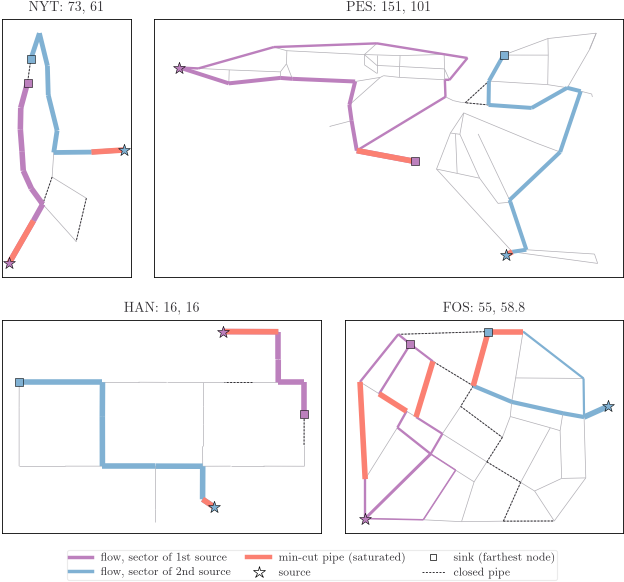

In [5]:
fig, axes = plot.instance_axes(nets)
for name, ax in axes.items():
    net = nets[name]
    _, dn = res[name]
    vmax = max(abs(f) for r in dn.values() for f in r['flows'].values())
    plot.pipes(ax, net, color=plot.GRID, lw=0.5)
    plot.pipes(ax, net, secs[name]['closed'], color=plot.INK, lw=0.7, linestyles=(0, (2, 1.5)))
    for k, (s, r) in enumerate(dn.items()):
        used = [(u, v, c) for u, v, c in r['pipes'] if abs(r['flows'][(u, v)]) > 1e-9]
        plot.pipes(ax, net, used, color=plot.SECTOR[k], lw=[0.6 + 3.4 * abs(r['flows'][p[:2]]) / vmax for p in used])
        plot.pipes(ax, net, r['cut'], color=plot.HIGHLIGHT, lw=4.0, zorder=2.5)
        plot.nodes(ax, net, [s], color=plot.SECTOR[k], s=80, marker='*', zorder=5)
        plot.nodes(ax, net, [r['sink']], color=plot.SECTOR[k], s=40, marker='s', zorder=5)
    plot.frame(ax, f'{name}: ' + ', '.join(f'{r["value"]:g}' for r in dn.values()))
h = [plt.Line2D([], [], color=plot.SECTOR[0], lw=2.5, label='flow, sector of 1st source'),
     plt.Line2D([], [], color=plot.SECTOR[1], lw=2.5, label='flow, sector of 2nd source'),
     plt.Line2D([], [], color=plot.HIGHLIGHT, lw=3.2, label='min-cut pipe (saturated)'),
     plt.Line2D([], [], ls='', marker='*', mfc='w', mec='k', mew=0.5, ms=9, label='source'),
     plt.Line2D([], [], ls='', marker='s', mfc='w', mec='k', mew=0.5, ms=5, label='sink (farthest node)'),
     plt.Line2D([], [], color=plot.INK, lw=0.7, ls=(0, (2, 1.5)), label='closed pipe')]
fig.legend(handles=h, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3)
plot.save(fig, 'flows')
plt.show()

## Complexity
Edmonds-Karp: $O(VE)$ augmentations of $O(E)$ each, $O(VE^2)$. Dinic: at most $V-1$ phases, each a BFS plus a blocking flow in $O(VE)$, so $O(V^2E)$. Both use $O(V+E)$ memory for the residual graph. On these sectors the bounds are far from tight: no sector needs more than 4 augmentations, so both run in a few BFS passes (timed in `08_performance`).

## Interpretation
In six of the eight sectors the minimum cut is a single pipe at a leaf: the only pipe leaving the source (NYT, HAN, PES source 7) or entering the sink (PES 10). There the rest of the sector is irrelevant to throughput, and in five of them the maximum flow equals what the task 4 shortest route carries on its own. PES source 1 already shows the difference between the two problems: its shortest route is limited to 101 by one narrow pipe, but a second route into node 11 lets 151 units reach node 10, saturating the sink pipe. FOS is where the mesh matters most: the source-7 sector has three disjoint bottleneck pipes that together carry 55, against 19 on the shortest route alone, and the source-37 sector carries 58.8 against 17.

Making the cut pipes unlimited raises the flow only to the next bottleneck in the table. In HAN that next bottleneck is again 16, because the routes are chains of 16-capacity pipes: upgrading one pipe gains nothing, the whole chain would have to be upgraded. In NYT, FOS and PES upgrading the cut pipes raises the deliverable flow by between 15% (FOS source 7, 55 to 63) and 259% (FOS source 37, 58.8 to 211), which tells an engineer which pipes to enlarge first and how much is gained.